# River Flood Early Warning for Sri Lanka

Using only data that the Irrigation Department already publishes, can a machine-learning
model predict that a river gauge which is **not yet flooding** will reach its official minor-flood level within the next 6 hours, with fewer false alarms than the current threshold rules?

**Data.** Sri Lanka Irrigation Department, Hydrology & Disaster Management Division: near-hourly
water-level readings from 39 river gauges in 18 river basins, Nov 2025 – Oct 2026
(296,111 readings). The department publishes it on a live ArcGIS dashboard; it is archived
on GitHub at `nuuuwan/lk_irrigation`. Official alert / minor / major flood levels come
from the same source, so the labels are the government's own definitions.

In [ ]:
import sys, time, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
from src.features import (load_readings, load_stations, clean_readings, to_hourly, hampel_flags,
                          station_base_levels, build_features, FEATURES, FEATURE_DESCRIPTIONS, HORIZON_H)

warnings.filterwarnings("ignore")
pd.set_option("display.width", 160, "display.max_columns", 30)
sns.set_theme(style="whitegrid", context="notebook")
FIG = ROOT / "reports" / "figures"; FIG.mkdir(parents=True, exist_ok=True)
SEED = 42
def savefig(name):
    plt.savefig(FIG / f"{name}.png", dpi=150, bbox_inches="tight")

## 1. Load the data

In [ ]:
stations = load_stations(ROOT / "data/raw/stations.json", ROOT / "data/raw/rivers.json")
raw = load_readings(ROOT / "data/raw/readings.json.gz")
print(f"{len(raw):,} readings | {raw.station.nunique()} stations | {stations.basin.nunique()} river basins")
print("From", raw.t.min(), "to", raw.t.max(), "(Sri Lanka time)")
raw.head()

296,111 readings | 39 stations | 18 river basins
From 2025-11-23 11:01:09 to 2026-10-23 21:10:27 (Sri Lanka time)


,station,t,level
0,Badalgama,2025-11-23 11:05:42,4.65
1,Badalgama,2025-11-23 12:07:49,4.57
2,Badalgama,2025-11-23 13:12:09,4.39
3,Badalgama,2025-11-23 14:07:29,4.23
4,Badalgama,2025-11-23 15:06:42,4.12


In [ ]:
stations[["river_name", "basin", "alert", "minor", "major", "upstream"]]

,river_name,basin,alert,minor,major,upstream
name,,,,,,
Badalgama,Maha Oya,Maha Oya,5.0000,6.200,9.6000,[Giriulla]
Baddegama,Gin Ganga,Gin Ganga,3.5000,4.000,5.0000,[Thawalama]
Deraniyagala,Seethawaka Ganga,Kelani Ganga,4.8000,5.800,6.4000,[]
Dunamale,Aththanagalu Oya,Aththanagalu Oya,3.3000,4.400,5.5000,[]
Ellagawa,Kalu Ganga,Kalu Ganga,10.0000,10.700,12.2000,[Rathnapura]
Galgamuwa,Mee Oya,Mee Oya,4.8400,5.940,8.0000,[]
Giriulla,Maha Oya,Maha Oya,5.5000,6.500,7.5000,[]
Glencourse,Kelani Ganga,Kelani Ganga,15.0000,16.500,19.0000,"[Deraniyagala, Holombuwa, Kithulgala]"
Hanwella,Kelani Ganga,Kelani Ganga,7.0000,8.000,10.0000,[Glencourse]


Each station has three official thresholds (metres). `upstream` lists the gauged stations directly
upstream, derived from the river network (each river's locations are ordered source → mouth).

## 2. Exploratory data analysis
### 2.1 Coverage and sampling frequency

In [ ]:
raw["gap_h"] = raw.groupby("station").t.diff().dt.total_seconds() / 3600
cov = raw.groupby("station").agg(readings=("level", "size"), median_gap_h=("gap_h", "median"),
                                 max_gap_h=("gap_h", "max"), min_level=("level", "min"),
                                 median_level=("level", "median"), max_level=("level", "max"))
cov.sort_values("readings").round(2)

,readings,median_gap_h,max_gap_h,min_level,median_level,max_level
station,,,,,,
Thanthirimale,4100,1.00,65.97,0.34,1.28,10.95
Galgamuwa,4214,1.00,86.97,-0.13,0.16,6.12
Weraganthota,4270,1.00,164.16,-3.93,-2.99,8.37
Kalawellawa (Millakanda),7199,1.00,86.17,0.00,2.38,8.78
Putupaula,7312,1.00,42.11,0.00,0.70,5.72
Padiyathalawa,7453,1.00,58.48,0.00,0.22,8.00
Yaka Wewa,7532,1.00,38.33,0.00,0.56,8.56
Horowpothana,7590,1.00,82.41,1.08,1.54,8.40
Peradeniya,7683,1.00,253.22,0.44,1.81,10.56


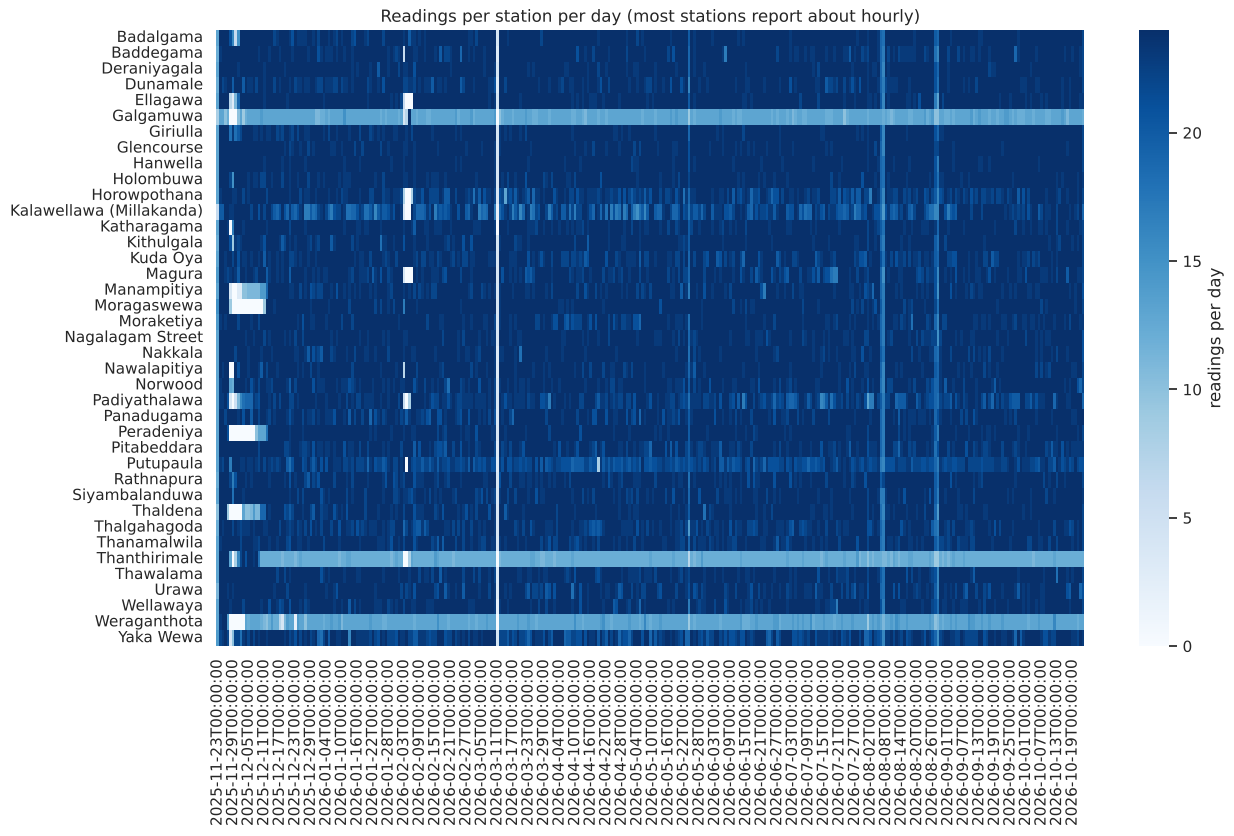

In [ ]:
daily = raw.assign(day=raw.t.dt.floor("D")).groupby(["station", "day"]).size().unstack(fill_value=0)
plt.figure(figsize=(14, 8))
sns.heatmap(daily.clip(upper=24), cmap="Blues", cbar_kws={"label": "readings per day"})
plt.title("Readings per station per day (most stations report about hourly)"); plt.xlabel(""); plt.ylabel("")
savefig("eda_coverage"); plt.show()

Most stations report roughly every hour (median gap ≈ 1 h). There are occasional outages
(one day-long outage affects all stations at once, e.g. 11 Mar and 7 Aug 2026), and Galgamuwa,
Thanthirimale and Weraganthota report about half as often. Gaps are handled in preprocessing.

### 2.2 Water levels and floods over time

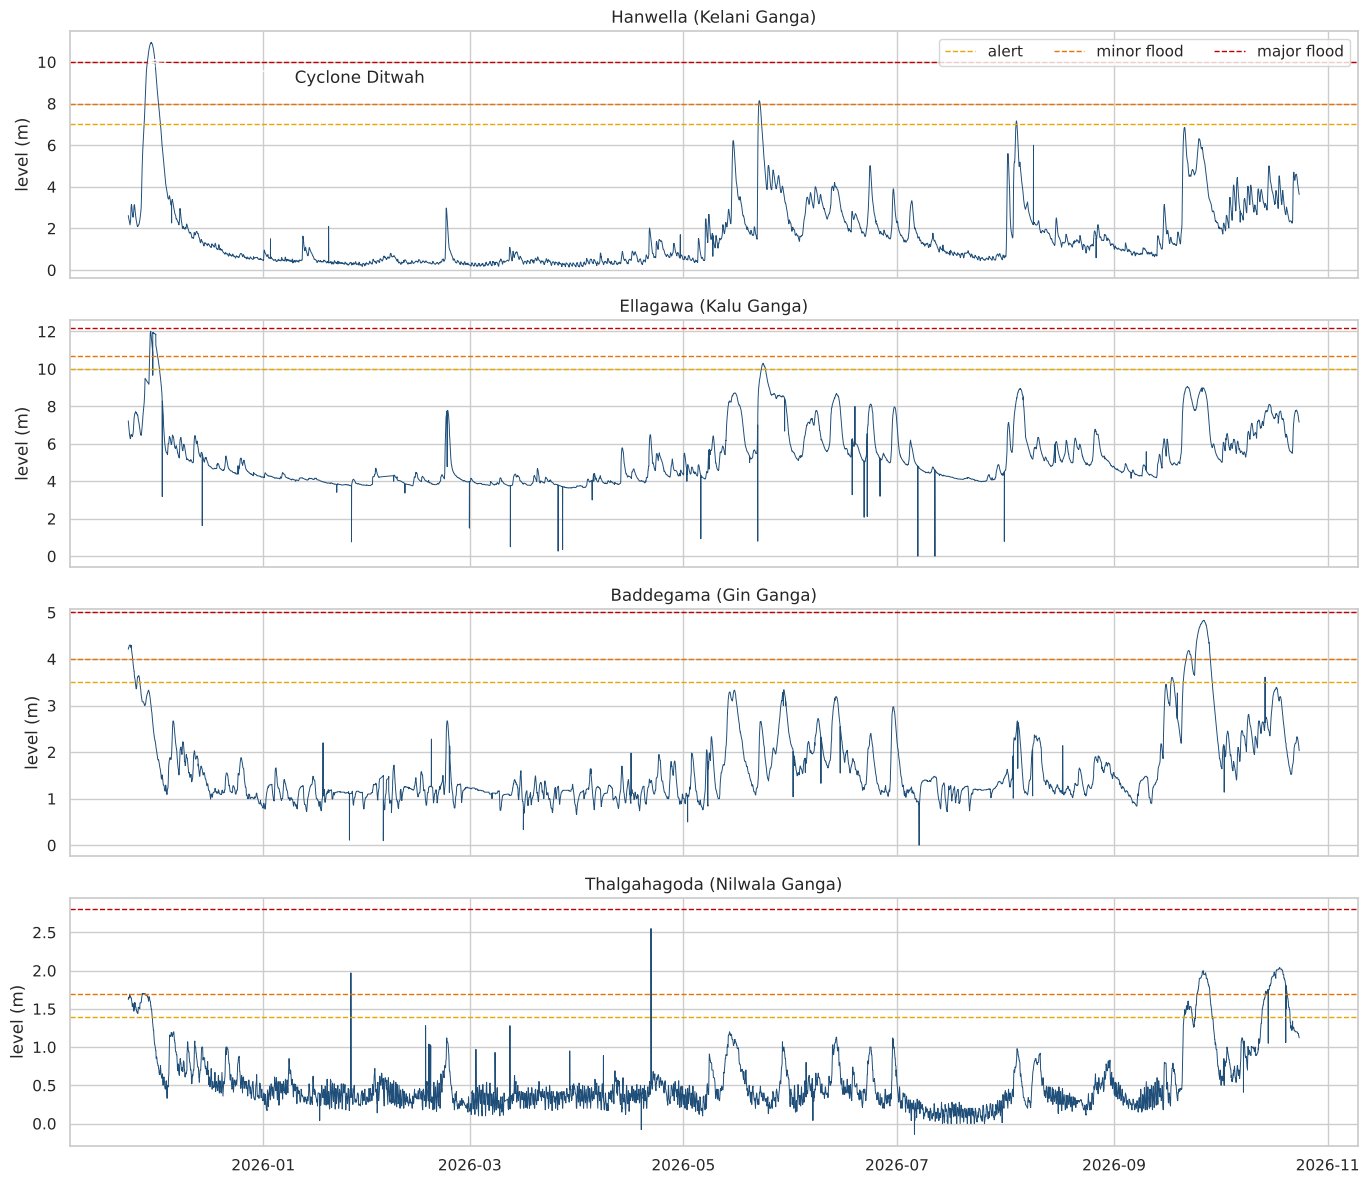

In [ ]:
fig, axes = plt.subplots(4, 1, figsize=(14, 12), sharex=True)
for ax, name in zip(axes, ["Hanwella", "Ellagawa", "Baddegama", "Thalgahagoda"]):
    s = stations.loc[name]; g = raw[raw.station == name]
    ax.plot(g.t, g.level, lw=0.7, color="#1f4e79")
    for lvl, c, lab in [(s.alert, "#e6a700", "alert"), (s.minor, "#e67300", "minor flood"), (s.major, "#c00000", "major flood")]:
        ax.axhline(lvl, color=c, ls="--", lw=1, label=lab)
    ax.set_title(f"{name} ({s.river_name})"); ax.set_ylabel("level (m)")
axes[0].legend(loc="upper right", ncol=3)
axes[0].annotate("Cyclone Ditwah", xy=(pd.Timestamp("2025-11-28"), stations.loc["Hanwella"].major),
                 xytext=(pd.Timestamp("2026-01-10"), 9), arrowprops=dict(arrowstyle="->"))
plt.tight_layout(); savefig("eda_levels"); plt.show()

status
normal         290055
alert            3673
minor flood      1824
major flood       559


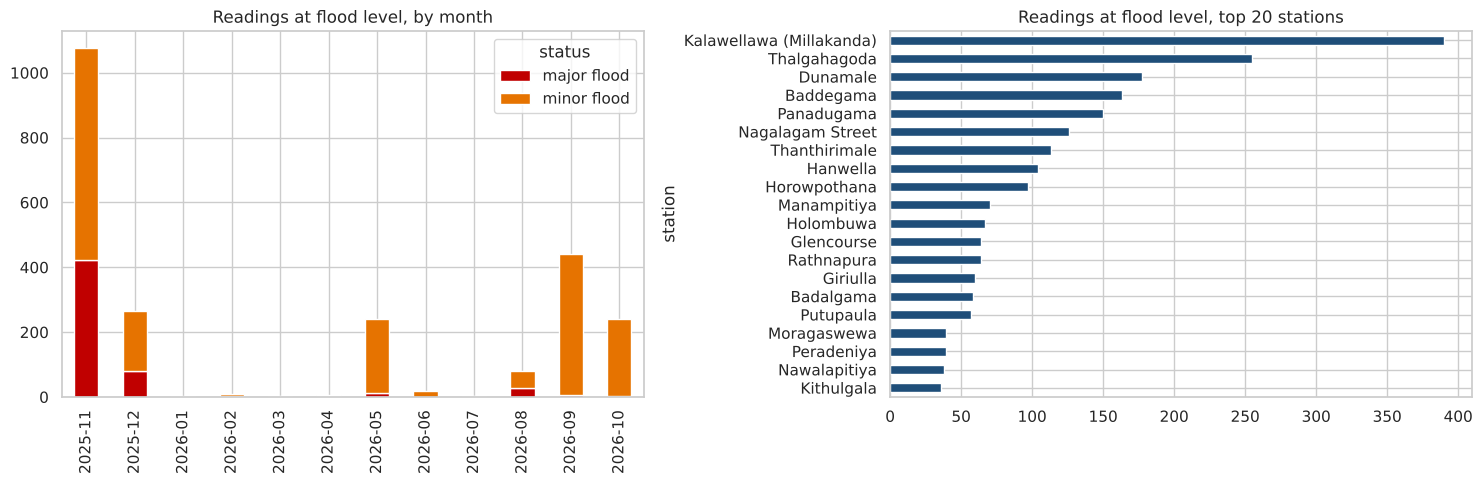

In [ ]:
st_thr = stations[["alert", "minor", "major"]]
lab = raw.join(st_thr, on="station")
lab["status"] = np.select([lab.level >= lab.major, lab.level >= lab.minor, lab.level >= lab.alert],
                          ["major flood", "minor flood", "alert"], "normal")
print(lab.status.value_counts().to_string())
fl = lab[lab.status.isin(["minor flood", "major flood"])]
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
fl.groupby([fl.t.dt.to_period("M").astype(str), "status"]).size().unstack(fill_value=0).plot.bar(stacked=True, ax=axes[0], color=["#c00000", "#e67300"])
axes[0].set_title("Readings at flood level, by month"); axes[0].set_xlabel("")
fl.station.value_counts().head(20).plot.barh(ax=axes[1], color="#1f4e79"); axes[1].invert_yaxis()
axes[1].set_title("Readings at flood level, top 20 stations")
plt.tight_layout(); savefig("eda_flood_counts"); plt.show()

**Observations.**
* Floods are rare: about **0.8%** of readings are at minor or major flood level, so this is a
  heavily imbalanced problem — accuracy would be a meaningless metric (always predicting
  "no flood" is >99% accurate). We use precision–recall based metrics instead.
* Floods cluster in a few weather events: **Cyclone Ditwah (late Nov 2025)**, the south-west monsoon
  onset (**May 2026**) and **Sept–Oct 2026**. Many rivers flood at the same time, which suggests a
  national "how many rivers are rising" signal is useful.
* The southern and western rivers (Kalu, Nilwala, Gin, Kelani, Attanagalu) flood most often.

### 2.3 How flood waves travel downstream
If upstream gauges rise before downstream ones, upstream readings carry early-warning information.
We cross-correlate hourly rises at upstream/downstream pairs.

In [ ]:
hr = raw.assign(t=raw.t.dt.floor("h")).groupby(["station", "t"])["level"].last().unstack(0).asfreq("h").ffill(limit=3)
pairs = [("Glencourse", "Hanwella"), ("Hanwella", "Nagalagam Street"), ("Rathnapura", "Ellagawa"),
         ("Ellagawa", "Putupaula"), ("Pitabeddara", "Panadugama"), ("Panadugama", "Thalgahagoda"),
         ("Thawalama", "Baddegama"), ("Giriulla", "Badalgama")]
rows = []
for up, down in pairs:
    du, dd = hr[up].diff(), hr[down].diff()
    cc = {lag: du.shift(lag).corr(dd) for lag in range(0, 13)}
    best = max(cc, key=cc.get)
    rows.append({"upstream": up, "downstream": down, "best_lag_h": best, "corr_at_best_lag": round(cc[best], 2), "corr_lag0": round(cc[0], 2)})
lags = pd.DataFrame(rows); lags

,upstream,downstream,best_lag_h,corr_at_best_lag,corr_lag0
0,Glencourse,Hanwella,3,0.58,0.29
1,Hanwella,Nagalagam Street,8,0.11,0.02
2,Rathnapura,Ellagawa,3,0.08,0.01
3,Ellagawa,Putupaula,1,0.09,-0.09
4,Pitabeddara,Panadugama,2,0.04,0.03
5,Panadugama,Thalgahagoda,4,0.03,0.01
6,Thawalama,Baddegama,6,0.11,-0.01
7,Giriulla,Badalgama,4,0.42,0.07


Downstream gauges respond to upstream rises **several hours later** (e.g. Glencourse → Hanwella),
confirming that upstream readings are useful features for a 6-hour warning.

### 2.4 What happens before a flood?
Compare rate of rise in the 3 hours **before** a station enters flood with ordinary hours.

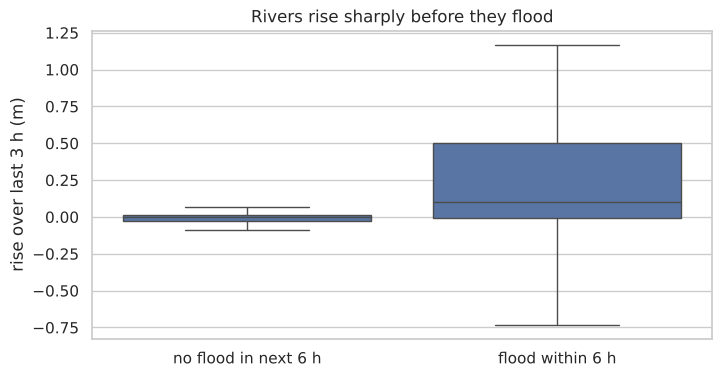

In [ ]:
tmp = []
for name in hr.columns:
    s = stations.loc[name]; x = hr[name]
    d = pd.DataFrame({"rise_3h": x - x.shift(3), "flood_in_6h": (pd.concat([x.shift(-k) for k in range(1, 7)], axis=1).max(axis=1) >= s.minor),
                      "flood_now": x >= s.minor})
    tmp.append(d[~d.flood_now].dropna())
pre = pd.concat(tmp)
plt.figure(figsize=(8, 4))
sns.boxplot(data=pre.sample(50000, random_state=SEED).pipe(lambda d: pd.concat([d, pre[pre.flood_in_6h]])),
            x="flood_in_6h", y="rise_3h", showfliers=False)
plt.xticks([0, 1], ["no flood in next 6 h", "flood within 6 h"]); plt.xlabel(""); plt.ylabel("rise over last 3 h (m)")
plt.title("Rivers rise sharply before they flood"); savefig("eda_rise_before_flood"); plt.show()

## 3. Preprocessing


In [ ]:
clean, report = clean_readings(raw.drop(columns="gap_h"), stations)
report

{'raw_rows': 296111,
 'unknown_station_rows': 0,
 'duplicates': 0,
 'spikes_removed': 650,
 'clean_rows': 295461}

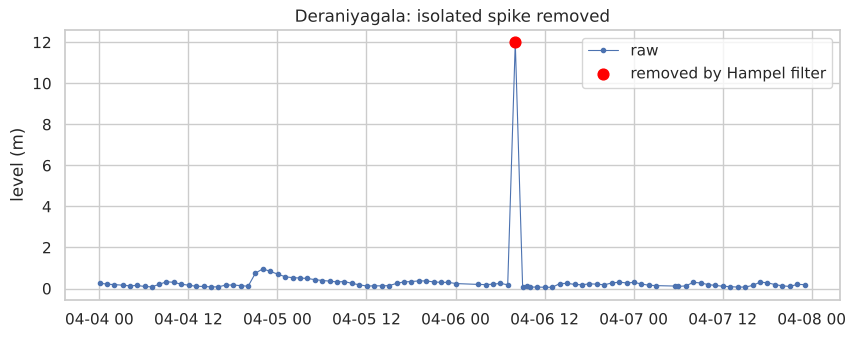

In [ ]:
g = raw[(raw.station == "Deraniyagala") & raw.t.between("2026-04-04", "2026-04-08")].copy()
g["spike"] = hampel_flags(g.level).values
plt.figure(figsize=(10, 3.5)); plt.plot(g.t, g.level, ".-", lw=0.8, label="raw")
plt.scatter(g.t[g.spike], g.level[g.spike], color="red", s=60, zorder=3, label="removed by Hampel filter")
plt.legend(); plt.title("Deraniyagala: isolated spike removed"); plt.ylabel("level (m)"); savefig("prep_spike"); plt.show()

**3.2 Regular hourly grid.** Readings arrive at irregular times. We keep the last reading in each
hour and forward-fill gaps of **at most 3 hours**; longer gaps stay missing and those rows are dropped
(no information is invented during long outages).

In [ ]:
hourly = to_hourly(clean)
print(f"{len(hourly):,} station-hours; missing after forward-fill: {hourly.level.isna().mean():.1%}")

313,034 station-hours; missing after forward-fill: 3.8%


**3.3 Normalisation across stations.** Gauges have very different datums: Glencourse floods at 16.5 m,
Nagalagam Street at 1.5 m. A raw metre value means nothing across stations. Every level is therefore
rescaled per station to a **0–1 "position" scale: 0 = the station's normal (median) level, 1 = its
official minor-flood level.** Rises are expressed as fractions of the same margin. The median is
computed from the **training period only** to avoid leakage. For distance- and gradient-based models
(logistic regression, KNN, SVM), features are additionally standardised with `StandardScaler` inside
a pipeline that is fit on training data only.

## 4. Feature engineering and target
A two-stage warning design. When a river gauge has already reached its minor-flood level, predicting that flooding will continue over the next 6 hours is relatively easy. A simple persistence rule achieves over 95% accuracy in predicting these hours, as shown in Section 6. However, the more challenging and valuable task is to predict new flood events: determining whether a river that is not currently flooding will reach its minor-flood level within the next 6 hours. Therefore, the focus is on predicting the onset of flooding rather than simply identifying its continuation.

* **Stage 1 (rule):** level ≥ minor-flood level → status "flooding now".
* **Stage 2 (machine learning):** for every hour when the river is **not** flooding,
  predict `y = 1` if it reaches minor-flood level at any time in the next 6 hours (t+1 … t+6).

A first version trained one model on all hours. It scored a high PR-AUC (≈0.93), but almost all of
that came from easy "already flooding" hours, and it warned of new floods only ~1 hour ahead,
later than the alert rule. Restricting the ML task to not-yet-flooding hours fixed this (section 8).

**Features (all known at time t — no look-ahead):**

In [ ]:
pd.DataFrame({"feature": FEATURES, "meaning": [FEATURE_DESCRIPTIONS[f] for f in FEATURES]})

,feature,meaning
0,pos_now,Current level on a 0-1 scale: 0 = station's no...
1,rise_1h,Change in level over the last 1 h (as a fracti...
2,rise_3h,Change in level over the last 3 h (fraction of...
3,rise_6h,Change in level over the last 6 h (fraction of...
4,rise_12h,Change in level over the last 12 h (fraction o...
5,rise_24h,Change in level over the last 24 h (fraction o...
6,accel_3h,Acceleration: last-3h rise minus the previous-...
7,pos_max_24h,Highest level (0-1 scale) in the last 24 h
8,pos_std_6h,Variability of the level over the last 6 h
9,up_pos_max,Highest current level (0-1 scale) at the gauge...


Calendar features (month, hour) were **deliberately excluded**: with only 11 months of data a model
could memorise the dates of particular storms instead of learning river behaviour. The national
counts (`n_alert_national`, `n_rising_national`) capture "a weather system is active" without dates.

In [ ]:
TEST_START = pd.Timestamp("2026-08-01")
base = station_base_levels(hourly[hourly.t < pd.Timestamp("2026-05-01")])   # normal levels from the first months only
data_all = build_features(hourly, stations, base).dropna(subset=FEATURES + ["y"]).reset_index(drop=True)
data_all["split"] = np.where(data_all.t < TEST_START, "dev", "test")
data_all.to_parquet(ROOT / "data/processed/features.parquet", index=False)

# Stage 1 check: when a river is already flooding, does persistence work?
fl_now = data_all[data_all.is_flood == 1]
print(f"Hours already at flood level: {len(fl_now):,}; still flooding within the next 6 h: {fl_now.y.mean():.1%}")

data = data_all[data_all.is_flood == 0].reset_index(drop=True)   # Stage 2: the ML task
data["month"] = data.t.dt.to_period("M").astype(str)
print(f"Stage-2 rows (not flooding yet): {len(data):,}; new-flood positives: {int(data.y.sum())} ({data.y.mean():.2%})")
data[FEATURES].describe().T.round(3)

Hours already at flood level: 2,192; still flooding within the next 6 h: 97.5%
Stage-2 rows (not flooding yet): 278,202; new-flood positives: 404 (0.15%)


,count,mean,std,min,25%,50%,75%,max
pos_now,278202.0,0.058,0.183,-0.594,-0.035,0.011,0.109,0.999
rise_1h,278202.0,-0.000,0.022,-0.506,-0.003,0.000,0.000,0.693
rise_3h,278202.0,-0.000,0.050,-1.310,-0.007,0.000,0.002,0.960
rise_6h,278202.0,-0.000,0.073,-1.682,-0.012,-0.002,0.003,0.966
rise_12h,278202.0,-0.001,0.081,-1.686,-0.018,-0.002,0.007,0.980
rise_24h,278202.0,-0.001,0.100,-1.751,-0.021,-0.003,0.009,1.212
accel_3h,278202.0,0.000,0.068,-1.641,-0.004,0.000,0.005,1.167
pos_max_24h,278202.0,0.111,0.218,-0.577,-0.018,0.046,0.180,2.298
pos_std_6h,278202.0,0.014,0.027,0.000,0.001,0.004,0.014,0.675
up_pos_max,278202.0,0.062,0.168,-0.594,-0.029,0.015,0.106,2.298


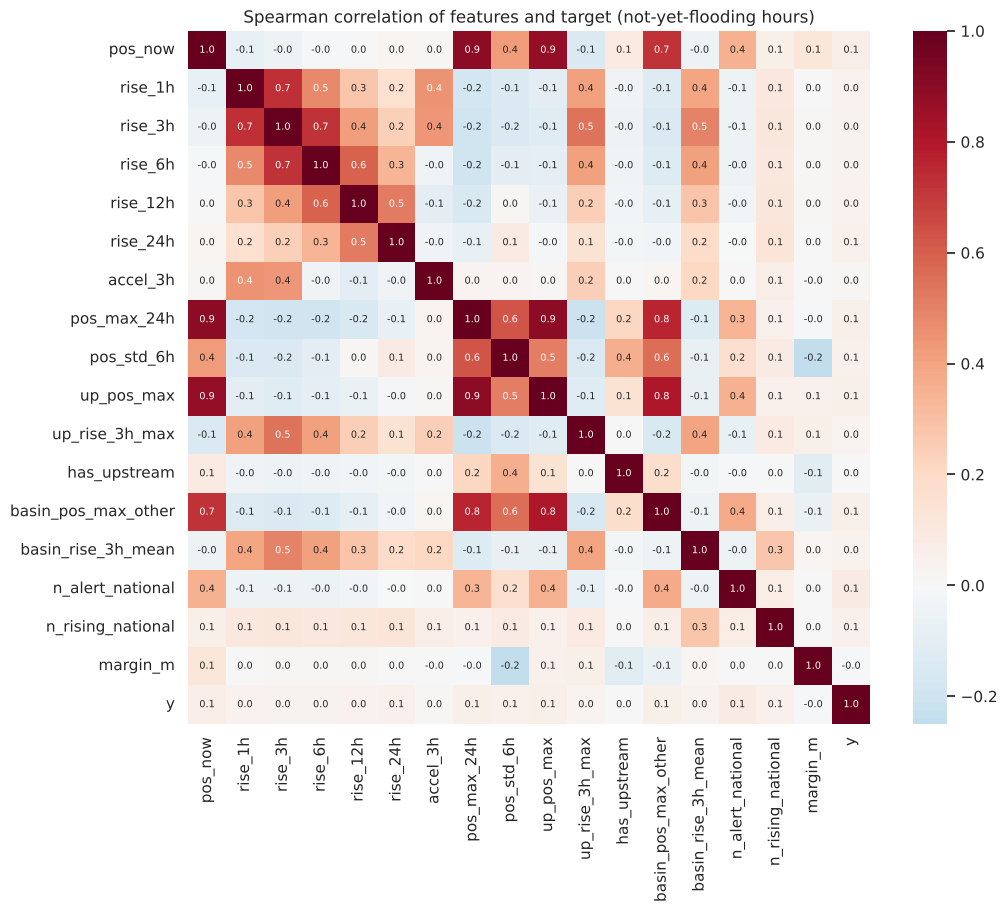

In [ ]:
plt.figure(figsize=(11, 9))
sns.heatmap(data[FEATURES + ["y"]].corr(method="spearman"), cmap="RdBu_r", center=0, annot=True, fmt=".1f", annot_kws={"size": 7})
plt.title("Spearman correlation of features and target (not-yet-flooding hours)"); savefig("eda_corr"); plt.show()

## 5. Development / test split and validation scheme
Random splitting would leak information (neighbouring hours are almost identical), so:

| set | period | role |
|---|---|---|
| development | 23 Nov 2025 – 31 Jul 2026 (Cyclone Ditwah, Dec 2025, May 2026 floods) | training, tuning, threshold and model choice |
| test | 1 Aug – 23 Oct 2026 (Aug, Sept, Oct 2026 floods) | final evaluation, used once |

**Blocked cross-validation by calendar month.** New-flood hours are rare and come in a few storms,
so a single validation window would hold only one or two storms. Instead, the development set is
split into 3 folds of **whole calendar months** (`GroupKFold`, group = month): an hour and its
neighbours are never on both sides of a fold, and every storm is used for validation once.

In [ ]:
from sklearn.model_selection import GroupKFold
dev, te = data[data.split == "dev"].reset_index(drop=True), data[data.split == "test"].reset_index(drop=True)
Xdev, ydev, gdev = dev[FEATURES], dev.y.astype(int), dev.month
Xte, yte = te[FEATURES], te.y.astype(int)
cv = GroupKFold(n_splits=3)
summary = pd.DataFrame({"rows": [len(dev), len(te)], "new-flood positives": [int(ydev.sum()), int(yte.sum())],
                        "positive rate": [ydev.mean(), yte.mean()]}, index=["development", "test"])
print(summary.to_string(formatters={"positive rate": "{:.2%}".format}))
print("\nPositives per month (development):", dev.groupby("month").y.sum().astype(int).to_dict())
print("Fold months:", [sorted(gdev.iloc[v].unique()) for _, v in cv.split(Xdev, ydev, gdev)])

               rows  new-flood positives positive rate
development  207925                  266         0.13%
test          70277                  138         0.20%

Positives per month (development): {'2025-11': 187, '2025-12': 12, '2026-01': 0, '2026-02': 6, '2026-03': 0, '2026-04': 0, '2026-05': 54, '2026-06': 6, '2026-07': 1}
Fold months: [['2025-12', '2026-03', '2026-07'], ['2025-11', '2026-01', '2026-04'], ['2026-02', '2026-05', '2026-06']]


## 6. Evaluation metrics and baselines
* PR-AUC (average precision) :- main, threshold-free metric for rare events (accuracy is useless:
  predicting "no flood" is >99.8% accurate).
* Recall / precision / F2 at a decision threshold. The threshold is chosen to maximise F2
  (recall weighted twice as much as precision — a missed flood costs more than a false alarm) on the
  out-of-fold development predictions, never on test.
* Event-level lead time:  for each flood onset, how many hours earlier the first warning came;
  and false-alarm hours. These are what an emergency manager cares about.

**Baselines** (what threshold rules can do today):
1. Persistence: "flooding later only if flooding now" :never warns of a new flood.
2. Alert rule: warn when the level is at or above the official **alert** level.
3. Alert + rising rule:  alert level **and** rising over the last 3 hours (a stricter rule).

In [ ]:
from sklearn.metrics import (average_precision_score, roc_auc_score, precision_score, recall_score,
                             f1_score, fbeta_score, precision_recall_curve, confusion_matrix)

def scores_of(model, X):
    return model.predict_proba(X)[:, 1] if hasattr(model, "predict_proba") else model.decision_function(X)

def best_f2_threshold(y, s):
    p, r, t = precision_recall_curve(y, s)
    f2 = 5 * p * r / np.maximum(4 * p + r, 1e-12)
    return t[np.nanargmax(f2[:-1])]

# flood onsets in the test period: first flood hour after >= 12 h below minor-flood level
test_all = data_all[data_all.split == "test"]
onsets = []
for name, g in test_all.groupby("station"):
    fl = g.set_index("t").asfreq("h").is_flood.fillna(0)
    prior = fl.shift(1).rolling(12, min_periods=1).max().fillna(0)
    onsets += [(name, T) for T in fl.index[(fl == 1) & (prior == 0)]]
onsets = pd.DataFrame(onsets, columns=["station", "onset"])
print(f"{len(onsets)} flood onsets at {onsets.station.nunique()} stations in the test period")

def lead_times(warn):
    w = te[["station", "t"]].assign(warn=warn).set_index(["station", "t"]).warn
    out = []
    for _, r in onsets.iterrows():
        hours = [h for h in range(1, 7) if w.get((r.station, r.onset - pd.Timedelta(hours=h)), 0) == 1]
        out.append(max(hours) if hours else 0)
    return np.array(out)

def evaluate(name, y, s, thr):
    pred = (s >= thr).astype(int)
    lt = lead_times(pred)
    return {"model": name, "PR-AUC": average_precision_score(y, s), "ROC-AUC": roc_auc_score(y, s),
            "precision": precision_score(y, pred, zero_division=0), "recall": recall_score(y, pred),
            "F2": fbeta_score(y, pred, beta=2), "false-alarm hours": int(((pred == 1) & (y == 0)).sum()),
            "onsets warned ≥1 h": (lt >= 1).mean(), "onsets warned ≥3 h": (lt >= 3).mean(),
            "median lead (h)": float(np.median(lt))}

te["alert_rising"] = ((te.is_alert == 1) & (te.rise_3h > 0)).astype(int)
results_test = [evaluate("Baseline: persistence", yte.values, np.zeros(len(te)), 0.5),
                evaluate("Baseline: alert rule", yte.values, te.is_alert.values, 0.5),
                evaluate("Baseline: alert + rising", yte.values, te.alert_rising.values, 0.5)]
pd.DataFrame(results_test).set_index("model").round(3)

22 flood onsets at 10 stations in the test period


,PR-AUC,ROC-AUC,precision,recall,F2,false-alarm hours,onsets warned ≥1 h,onsets warned ≥3 h,median lead (h)
model,,,,,,,,,
Baseline: persistence,0.002,0.500,0.000,0.000,0.000,0,0.000,0.000,0.0
Baseline: alert rule,0.043,0.827,0.064,0.674,0.231,1371,0.909,0.727,6.0
Baseline: alert + rising,0.065,0.761,0.121,0.529,0.317,528,0.909,0.682,3.0


The alert rule warns of every onset hours ahead — but it fires on well over a thousand
station-hours that never become floods (its precision is only a few percent). A useful model has to
keep most of that early warning while cutting the false alarms.

## 7. The new algorithm: Extremely Randomized Trees (Extra Trees)

**Why it was selected.**
* Flood risk is a sharp, interacting threshold effect, which tree ensembles model naturally.
* River gauges are noisy and there are only 266 new-flood hours for development. Extra Trees' extra
  randomisation is a strong guard against over-fitting those few events.
* It is fast, needs no feature scaling, and handles imbalance with

In [ ]:
from sklearn.model_selection import RandomizedSearchCV, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier
from sklearn.base import clone
from scipy.stats import loguniform, randint, uniform
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

from src.modeling import NegativeSubsampler   # fits KNN/SVM on all positives + 10,000 negatives

spw = float((ydev == 0).sum() / (ydev == 1).sum())
models = {
    "Logistic Regression": (make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000, class_weight="balanced")),
        {"logisticregression__C": loguniform(1e-3, 10)}, 8, False),
    "K-Nearest Neighbours": (NegativeSubsampler(make_pipeline(StandardScaler(), KNeighborsClassifier())),
        {"estimator__kneighborsclassifier__n_neighbors": [5, 15, 25, 51, 101], "estimator__kneighborsclassifier__weights": ["uniform", "distance"]}, 6, True),
    "SVM (RBF)": (NegativeSubsampler(make_pipeline(StandardScaler(), SVC(kernel="rbf", class_weight="balanced"))),
        {"estimator__svc__C": [0.1, 1, 10], "estimator__svc__gamma": ["scale", 0.02, 0.1]}, 5, True),
    "Decision Tree": (DecisionTreeClassifier(class_weight="balanced", random_state=SEED),
        {"max_depth": randint(3, 14), "min_samples_leaf": randint(10, 400)}, 12, False),
    "Random Forest": (RandomForestClassifier(n_estimators=200, class_weight="balanced_subsample", n_jobs=-1, random_state=SEED),
        {"max_depth": [6, 10, 16, None], "min_samples_leaf": [3, 10, 30, 80], "max_features": ["sqrt", 0.5]}, 6, False),
    "Extra Trees": (ExtraTreesClassifier(n_estimators=200, class_weight="balanced_subsample", n_jobs=-1, random_state=SEED),
        {"max_depth": [6, 10, 16, None], "min_samples_leaf": [3, 10, 30, 80], "max_features": ["sqrt", 0.5, 1.0]}, 6, False),
    "XGBoost": (XGBClassifier(tree_method="hist", n_jobs=2, random_state=SEED),
        {"n_estimators": randint(150, 500), "max_depth": randint(2, 7), "learning_rate": loguniform(0.02, 0.2),
         "subsample": uniform(0.6, 0.4), "colsample_bytree": uniform(0.5, 0.5), "min_child_weight": randint(1, 30),
         "scale_pos_weight": [1, 5, 20, spw]}, 14, False),
    "LightGBM": (LGBMClassifier(n_jobs=2, verbose=-1, random_state=SEED),
        {"n_estimators": randint(150, 500), "num_leaves": randint(4, 32), "learning_rate": loguniform(0.02, 0.2),
         "min_child_samples": randint(20, 300), "subsample": uniform(0.6, 0.4), "subsample_freq": [1],
         "colsample_bytree": uniform(0.5, 0.5), "reg_lambda": loguniform(1e-2, 30), "scale_pos_weight": [1, 5, 20]}, 14, False),
}

fitted, tuning_rows, thresholds, oof = {}, [], {}, {}
for name, (est, grid, n_iter, sub) in models.items():
    t0 = time.time()
    X, y, g = Xdev, ydev, gdev
    search = RandomizedSearchCV(est, grid, n_iter=n_iter, scoring="average_precision", cv=cv, refit=False,
                                random_state=SEED, n_jobs=1)
    search.fit(X, y, groups=g)
    best = clone(est).set_params(**search.best_params_)
    if hasattr(best, "predict_proba"):
        s_oof = cross_val_predict(best, X, y, groups=g, cv=cv, method="predict_proba")[:, 1]
    else:
        s_oof = cross_val_predict(best, X, y, groups=g, cv=cv, method="decision_function")
    thresholds[name] = best_f2_threshold(y.values, s_oof)
    oof[name] = (y.values, s_oof)
    fitted[name] = clone(best).fit(X, y)
    tuning_rows.append({"model": name, "CV PR-AUC": search.best_score_,
                        "CV PR-AUC std": search.cv_results_["std_test_score"][search.best_index_],
                        "threshold (F2, out-of-fold)": thresholds[name], "best params": search.best_params_,
                        "tuning time (s)": round(time.time() - t0)})
    print(f"{name:22s} CV PR-AUC={search.best_score_:.3f}  ({time.time() - t0:.0f}s)")

tuning = pd.DataFrame(tuning_rows).set_index("model")
tuning.sort_values("CV PR-AUC", ascending=False)

Logistic Regression    CV PR-AUC=0.096  (16s)


K-Nearest Neighbours   CV PR-AUC=0.187  (29s)


SVM (RBF)              CV PR-AUC=0.146  (37s)


Decision Tree          CV PR-AUC=0.160  (12s)


Random Forest          CV PR-AUC=0.400  (175s)


Extra Trees            CV PR-AUC=0.484  (57s)


XGBoost                CV PR-AUC=0.437  (51s)


LightGBM               CV PR-AUC=0.441  (76s)


,CV PR-AUC,CV PR-AUC std,"threshold (F2, out-of-fold)",best params,tuning time (s)
model,,,,,
Extra Trees,0.483695,0.049564,0.104879,"{'min_samples_leaf': 3, 'max_features': 0.5, '...",57
LightGBM,0.441153,0.097472,0.023250,"{'colsample_bytree': 0.8636359979282104, 'lear...",76
XGBoost,0.437042,0.095827,0.089445,"{'colsample_bytree': 0.5979914312095727, 'lear...",51
Random Forest,0.399850,0.133125,0.109944,"{'min_samples_leaf': 3, 'max_features': 'sqrt'...",175
K-Nearest Neighbours,0.187038,0.124728,0.138614,{'estimator__kneighborsclassifier__weights': '...,29
Decision Tree,0.160446,0.007588,0.991403,"{'max_depth': 13, 'min_samples_leaf': 81}",12
SVM (RBF),0.145970,0.066763,0.486884,"{'estimator__svc__gamma': 0.02, 'estimator__sv...",37
Logistic Regression,0.095853,0.039360,0.875975,{'logisticregression__C': 0.0017073967431528124},16


### 7.2 Hyper-parameter choices for the selected model

| hyper-parameter | value | meaning and why |
|---|---|---|
| `n_estimators` | 200 (fixed) | number of trees; beyond ~200 the score stops improving and the model only gets slower |
| `max_features` | 0.5 | each split considers a random half of the 17 features: more variety between trees |
| `min_samples_leaf` | 3 | a leaf must hold at least 3 hours: allows detailed rules but not single-hour memorisation |
| `max_depth` | None | trees grow until leaves reach `min_samples_leaf`; depth is controlled by the leaf size instead |
| `class_weight` | `balanced_subsample` (fixed) | flood hours weigh ~780× more, re-balanced inside each tree |
| decision threshold | 0.105 | chosen to maximise F2 on out-of-fold predictions (section 6) |

## 8. Test-set evaluation and model selection


In [ ]:
test_scores = {}
for name, m in fitted.items():
    test_scores[name] = scores_of(m, Xte)
    results_test.append(evaluate(name, yte.values, test_scores[name], thresholds[name]))
test_table = pd.DataFrame(results_test).set_index("model")
test_table.round(3).to_csv(ROOT / "reports" / "test_results.csv")
BEST = tuning["CV PR-AUC"].idxmax()
print("Selected model (highest cross-validated PR-AUC):", BEST)
test_table.round(3)

Selected model (highest cross-validated PR-AUC): Extra Trees


,PR-AUC,ROC-AUC,precision,recall,F2,false-alarm hours,onsets warned ≥1 h,onsets warned ≥3 h,median lead (h)
model,,,,,,,,,
Baseline: persistence,0.002,0.500,0.000,0.000,0.000,0,0.000,0.000,0.0
Baseline: alert rule,0.043,0.827,0.064,0.674,0.231,1371,0.909,0.727,6.0
Baseline: alert + rising,0.065,0.761,0.121,0.529,0.317,528,0.909,0.682,3.0
Logistic Regression,0.128,0.968,0.070,0.775,0.257,1420,1.000,0.864,6.0
K-Nearest Neighbours,0.091,0.944,0.049,0.790,0.196,2122,1.000,0.864,6.0
SVM (RBF),0.128,0.957,0.034,0.855,0.145,3389,1.000,0.909,6.0
Decision Tree,0.100,0.766,0.140,0.435,0.306,369,0.955,0.591,3.0
Random Forest,0.133,0.915,0.151,0.493,0.339,383,0.955,0.591,3.0
Extra Trees,0.154,0.925,0.135,0.580,0.350,511,1.000,0.682,4.0


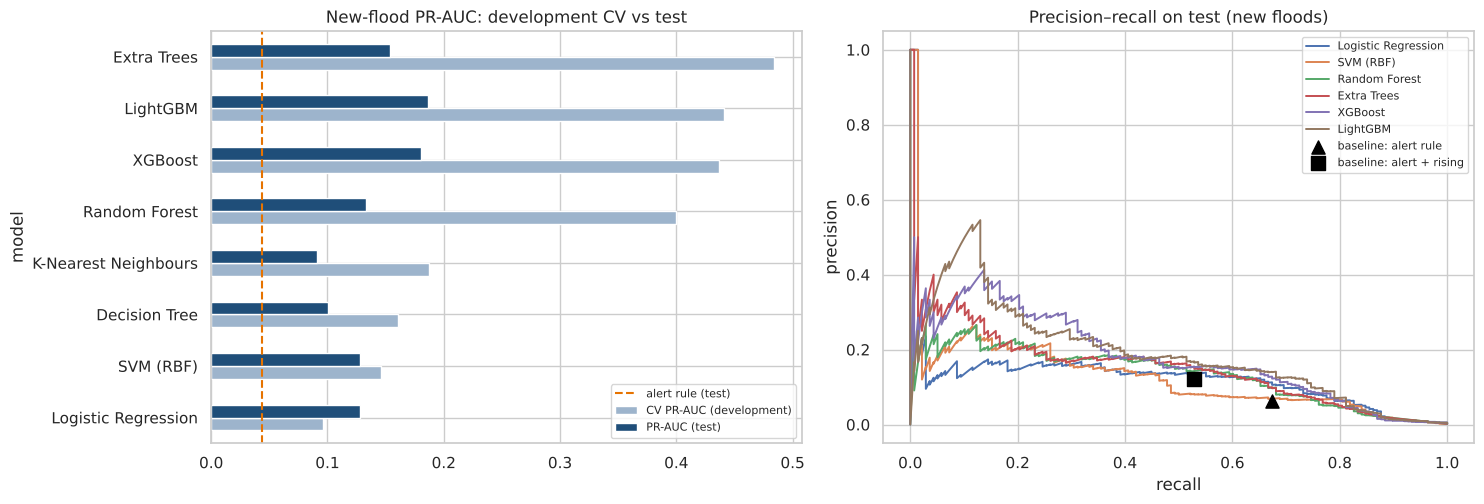

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.2))
ml = test_table.drop(index=[i for i in test_table.index if i.startswith("Baseline")])
comp = pd.DataFrame({"CV PR-AUC (development)": tuning["CV PR-AUC"], "PR-AUC (test)": ml["PR-AUC"]}).sort_values("CV PR-AUC (development)")
comp.plot.barh(ax=axes[0], color=["#9db4cc", "#1f4e79"])
axes[0].axvline(test_table.loc["Baseline: alert rule", "PR-AUC"], color="#e67300", ls="--", label="alert rule (test)")
axes[0].legend(fontsize=8, loc="lower right"); axes[0].set_title("New-flood PR-AUC: development CV vs test")
for name in ["Logistic Regression", "SVM (RBF)", "Random Forest", "Extra Trees", "XGBoost", "LightGBM"]:
    p, r, _ = precision_recall_curve(yte, test_scores[name]); axes[1].plot(r, p, label=name, lw=1.4)
for name, col, mk in [("alert rule", "is_alert", "^"), ("alert + rising", "alert_rising", "s")]:
    pr = te[col].values.astype(int); axes[1].scatter(recall_score(yte, pr), precision_score(yte, pr), marker=mk, s=90, color="black", label=f"baseline: {name}", zorder=5)
axes[1].set_xlabel("recall"); axes[1].set_ylabel("precision"); axes[1].set_title("Precision–recall on test (new floods)"); axes[1].legend(fontsize=8)
plt.tight_layout(); savefig("model_comparison"); plt.show()

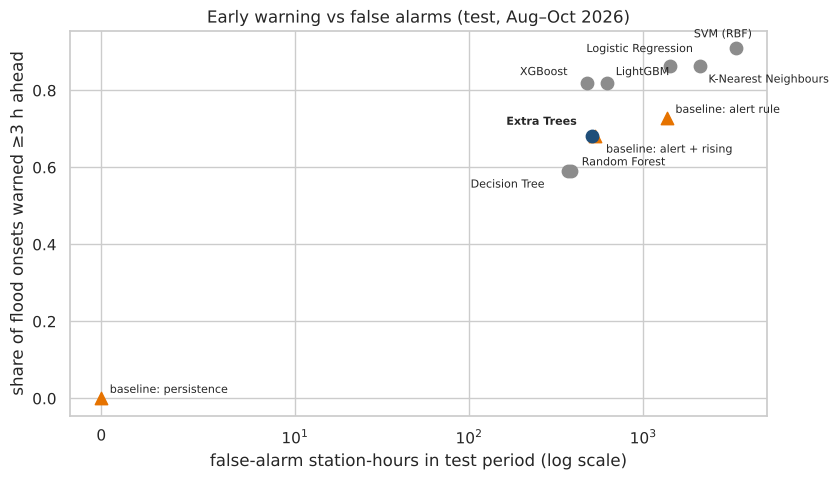

In [ ]:
fig, ax = plt.subplots(figsize=(9, 5))
tt = test_table.copy()
for name, r in tt.iterrows():
    base_ = name.startswith("Baseline")
    ax.scatter(r["false-alarm hours"], r["onsets warned ≥3 h"], s=80, marker="^" if base_ else "o",
               color="#e67300" if base_ else ("#1f4e79" if name == BEST else "#8c8c8c"), zorder=3)
    off = {"XGBoost": (-48, 6), "LightGBM": (6, 6), "Extra Trees": (-62, 8), "Baseline: alert + rising": (8, -12),
           "Decision Tree": (-70, -12), "Random Forest": (8, 4), "Logistic Regression": (-60, 10), "K-Nearest Neighbours": (6, -12),
           "SVM (RBF)": (-30, 8)}.get(name, (6, 4))
    ax.annotate(name.replace("Baseline: ", "baseline: "), (r["false-alarm hours"], r["onsets warned ≥3 h"]), xytext=off,
                textcoords="offset points", fontsize=8, fontweight="bold" if name == BEST else "normal")
ax.set_xscale("symlog", linthresh=10); ax.set_xlabel("false-alarm station-hours in test period (log scale)")
ax.set_ylabel("share of flood onsets warned ≥3 h ahead"); ax.set_title("Early warning vs false alarms (test, Aug–Oct 2026)")
savefig("warning_tradeoff"); plt.show()

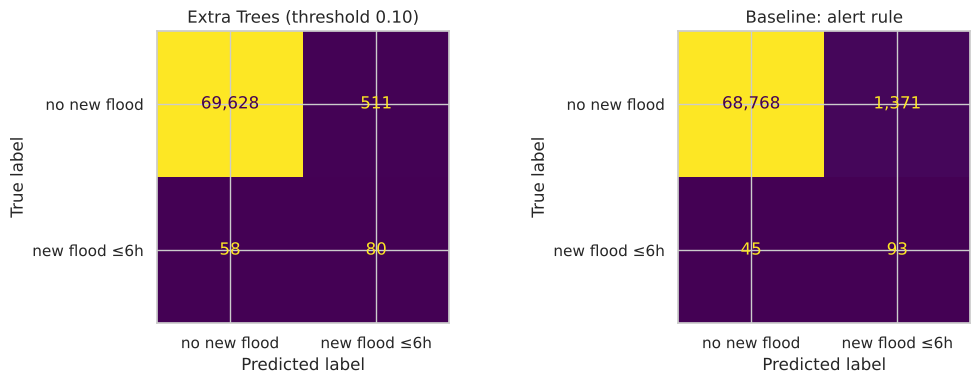

In [ ]:
from sklearn.metrics import ConfusionMatrixDisplay
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
ConfusionMatrixDisplay(confusion_matrix(yte, (test_scores[BEST] >= thresholds[BEST]).astype(int)), display_labels=["no new flood", "new flood ≤6h"]).plot(ax=axes[0], colorbar=False, values_format=",")
axes[0].set_title(f"{BEST} (threshold {thresholds[BEST]:.2f})")
ConfusionMatrixDisplay(confusion_matrix(yte, te.is_alert.astype(int)), display_labels=["no new flood", "new flood ≤6h"]).plot(ax=axes[1], colorbar=False, values_format=",")
axes[1].set_title("Baseline: alert rule"); plt.tight_layout(); savefig("confusion"); plt.show()

### 8.1 Lead time per flood onset (selected model vs alert rule)

In [ ]:
te["score"], te["warn"] = test_scores[BEST], (test_scores[BEST] >= thresholds[BEST]).astype(int)
events = onsets.assign(model_lead_h=lead_times(te.warn.values), alert_rule_lead_h=lead_times(te.is_alert.values))
events

,station,onset,model_lead_h,alert_rule_lead_h
0,Baddegama,2026-09-21 15:00:00,6,6
1,Baddegama,2026-09-24 05:00:00,4,6
2,Holombuwa,2026-08-01 05:00:00,1,0
3,Holombuwa,2026-08-03 15:00:00,1,1
4,Holombuwa,2026-10-08 19:00:00,1,1
5,Holombuwa,2026-10-14 18:00:00,1,0
6,Kalawellawa (Millakanda),2026-09-21 06:00:00,6,6
7,Kithulgala,2026-08-03 11:00:00,6,6
8,Nawalapitiya,2026-08-01 06:00:00,3,3
9,Nawalapitiya,2026-08-03 00:00:00,2,2


### 8.2 Bias check: does the model serve all regions equally?
Sri Lanka's south-west wet zone (Kelani, Kalu, Gin, Nilwala, Attanagalu, Maha Oya basins) floods
most often and produced most training examples. If the model learned mainly from those rivers, people
living along dry and intermediate zone rivers could get later or fewer warnings.

In [ ]:
WET = {"Kelani Ganga", "Kalu Ganga", "Gin Ganga", "Nilwala Ganga", "Aththanagalu Oya", "Maha Oya"}
zone_of = lambda b: "Wet zone (south-west)" if b in WET else "Dry & intermediate zone"
for df_ in (dev, te):
    df_["zone"] = df_.basin.map(zone_of)
ev_g = events.assign(basin=events.station.map(stations.basin))
ev_g["zone"] = ev_g.basin.map(zone_of)

def group_report(col):
    rows = []
    for k, g in te.groupby(col):
        e = ev_g[ev_g[col] == k]
        rows.append({col: k, "stations": g.station.nunique(),
                     "development new-flood hours": int(dev.loc[dev[col] == k, "y"].sum()),
                     "test new-flood hours": int(g.y.sum()), "test flood onsets": len(e),
                     "onsets warned ≥1 h": (e.model_lead_h >= 1).mean() if len(e) else np.nan,
                     "onsets warned ≥3 h": (e.model_lead_h >= 3).mean() if len(e) else np.nan,
                     "recall (hours)": g.loc[g.y == 1, "warn"].mean() if g.y.sum() else np.nan,
                     "false alarms per station-day": ((g.warn == 1) & (g.y == 0)).sum() / (len(g) / 24)})
    return pd.DataFrame(rows).set_index(col).round(3)

fair_zone, fair_basin = group_report("zone"), group_report("basin")
fair_zone.to_csv(ROOT / "reports" / "fairness_by_zone.csv"); fair_basin.to_csv(ROOT / "reports" / "fairness_by_basin.csv")
fair_zone

,stations,development new-flood hours,test new-flood hours,test flood onsets,onsets warned ≥1 h,onsets warned ≥3 h,recall (hours),false alarms per station-day
zone,,,,,,,,
Dry & intermediate zone,18,131,37,5,1.0,0.400,0.486,0.036
Wet zone (south-west),21,135,101,17,1.0,0.765,0.614,0.276


In [ ]:
fair_basin.sort_values("test new-flood hours", ascending=False)

,stations,development new-flood hours,test new-flood hours,test flood onsets,onsets warned ≥1 h,onsets warned ≥3 h,recall (hours),false alarms per station-day
basin,,,,,,,,
Nilwala Ganga,4,10,42,7,1.0,1.000,0.833,0.326
Mahaweli Ganga,5,36,37,5,1.0,0.400,0.486,0.124
Kelani Ganga,7,49,35,6,1.0,0.333,0.257,0.284
Gin Ganga,2,0,12,2,1.0,1.000,0.833,0.386
Kalu Ganga,5,46,12,2,1.0,1.000,0.667,0.243
Aththanagalu Oya,1,18,0,0,NaN,NaN,NaN,0.461
Deduru Oya,1,6,0,0,NaN,NaN,NaN,0.024
Kumbukkan Oya,1,18,0,0,NaN,NaN,NaN,0.000
Kirindi Oya,3,24,0,0,NaN,NaN,NaN,0.000


**Findings.**
* Unequal early warning. Every test flood onset in both zones got at least 1 hour of warning, but
  77% of wet-zone onsets were warned ≥3 h ahead against 40% in the dry and intermediate zone
  (recall 0.61 vs 0.49). Dry-zone communities would, on average, get less notice.
* Unequal false alarms. Wet-zone gauges raise about 0.28 false-alarm hours per station per day,
  dry-zone gauges about 0.04. The model is more "nervous" where floods are common and more cautious
  elsewhere. Warning fatigue is therefore a bigger risk in the wet zone.
* Unverified regions. 11 of the 18 basins had no test-period floods, so the model's performance
  there cannot be measured yet. Four basins (Gin, Heda, Mee and Walawe) had no new-flood hours in the
  development data either.

### 8.3 Interpretation and choice of model
* The single all-hours model looked excellent but was not useful. Its PR-AUC (≈0.93) came from
  hours that were already flooding. Reframing the task to *new* floods made the problem honest.
* Selected model: Extra Trees** — highest and most stable cross-validated PR-AUC (0.48 ± 0.05).
  On the untouched test period it warned of **all 22 flood onsets at least 1 h ahead (68% at least
  3 h; median 4 h) with **511 false-alarm station-hours versus 1,371 for the alert rule (−63%);
  its precision is double the alert rule's, and its PR-AUC 3.6× higher.
* XGBoost and LightGBM did slightly better on test (PR-AUC 0.18–0.19, 82% of onsets warned
  ≥3 h). With only a handful of test storms, that gap is within the noise; the model is kept as chosen
  by cross-validation so that the test set is never used for selection. Boosting is a strong alternative.
* Logistic regression, KNN and SVM reach high recall only by raising 1,400–3,400 false alarms :
  more than the alert rule. Flood risk is a sharp, interacting threshold effect (high and rising
  **and** a storm active), which tree ensembles learn naturally and linear or distance models do not.
* Single trees and Random Forest: few false alarms but later warnings.

## 9. Explainability with SHAP

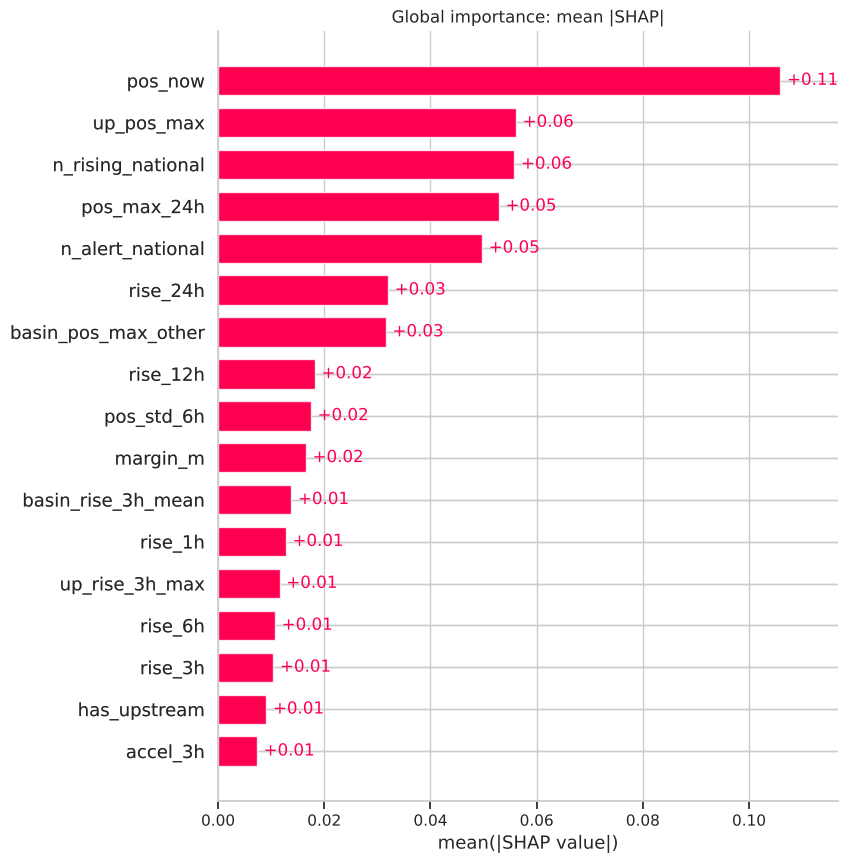

In [ ]:
import shap
best_model = fitted[BEST]
tree_model = BEST in {"Random Forest", "Extra Trees", "XGBoost", "LightGBM", "Decision Tree"}
rng = np.random.RandomState(SEED)
sample_idx = np.r_[np.where(yte == 1)[0], rng.choice(np.where(yte == 0)[0], 1500, replace=False)]
Xs = Xte.iloc[sample_idx]
if tree_model:
    explainer = shap.TreeExplainer(best_model)
    sv = explainer(Xs)
else:
    explainer = shap.Explainer(lambda X: scores_of(best_model, pd.DataFrame(X, columns=FEATURES)), shap.sample(Xdev, 200, random_state=SEED))
    Xs = Xs.iloc[:400]; sv = explainer(Xs)
if sv.values.ndim == 3:            # sklearn forests return one set per class
    sv = sv[:, :, 1]
plt.figure(); shap.plots.bar(sv, max_display=17, show=False); plt.title("Global importance: mean |SHAP|"); savefig("shap_bar"); plt.show()

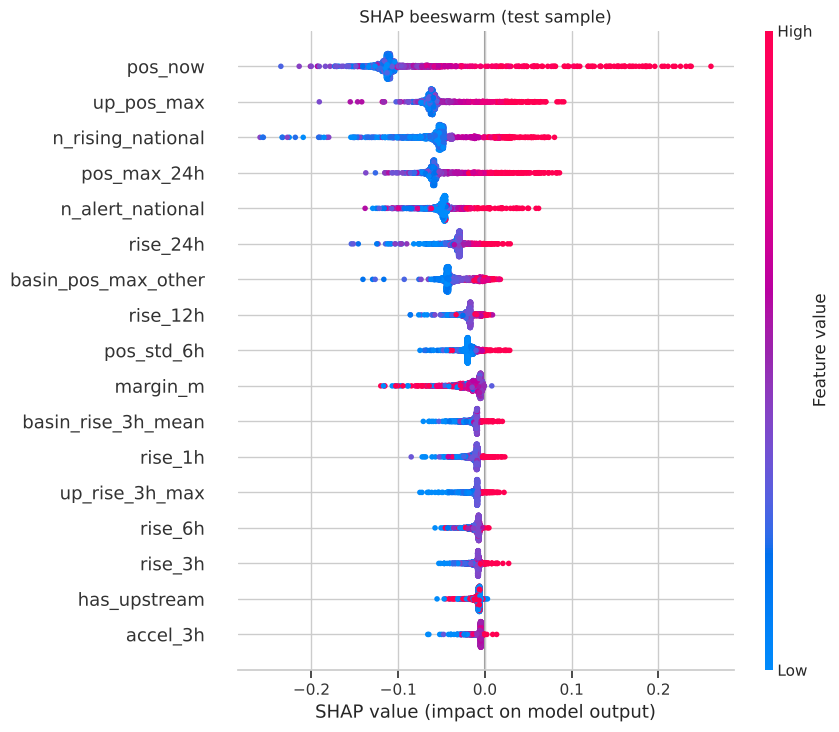

In [ ]:
plt.figure(); shap.plots.beeswarm(sv, max_display=17, show=False); plt.title("SHAP beeswarm (test sample)"); savefig("shap_beeswarm"); plt.show()

**Reading the beeswarm.** Each dot is one station-hour; red = high feature value, blue = low; dots to
the right push the prediction towards "new flood within 6 h".

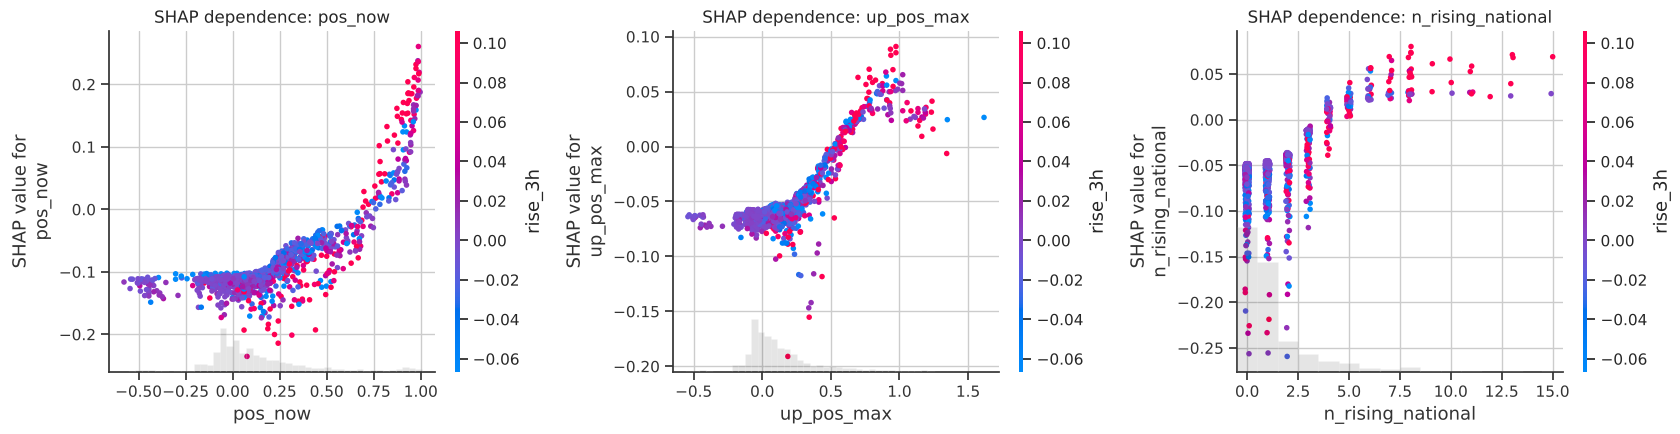

Top features: ['pos_now', 'up_pos_max', 'n_rising_national']


In [ ]:
top3 = list(pd.Series(np.abs(sv.values).mean(0), index=FEATURES).sort_values(ascending=False).index[:3])
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
for ax, f in zip(axes, top3):
    other = "rise_3h" if f != "rise_3h" else "pos_now"
    shap.plots.scatter(sv[:, f], color=sv[:, other], ax=ax, show=False)
    ax.set_title(f"SHAP dependence: {f}")
plt.tight_layout(); savefig("shap_dependence"); plt.show()
print("Top features:", top3)

### 9.1 Local explanation — one real warning
The test-period flood onset with the longest model lead time

Station Baddegama: flood onset 2026-09-21 15:00:00; explaining 2026-09-21 09:00:00 (probability 0.20, threshold 0.10)


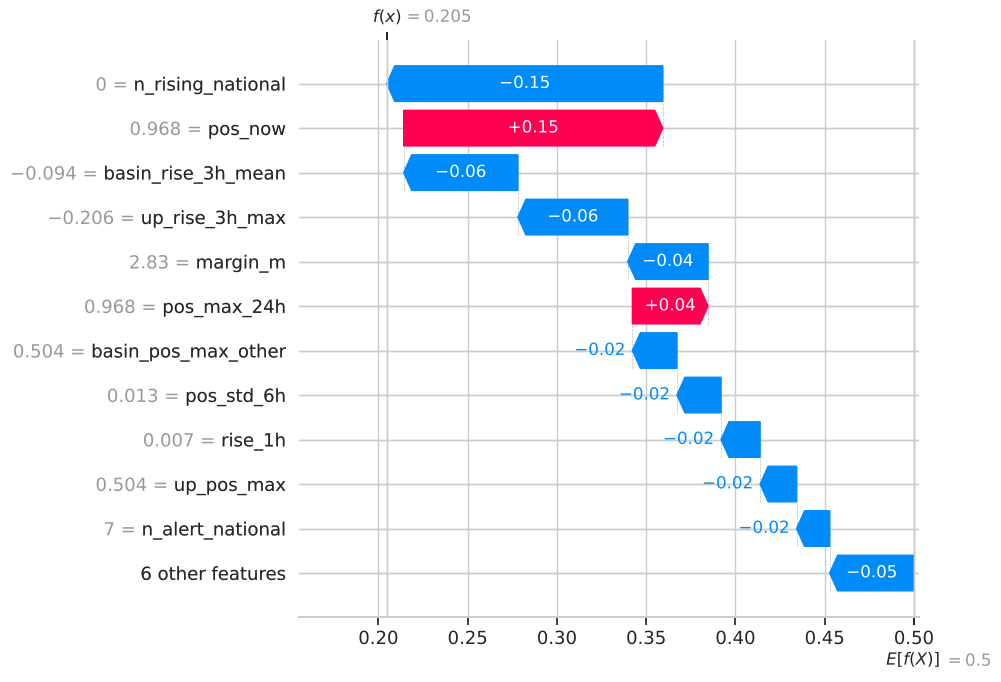

In [ ]:
ev = events.sort_values("model_lead_h", ascending=False).iloc[0]
cand = te[(te.station == ev.station) & (te.t >= ev.onset - pd.Timedelta(hours=6)) & (te.t < ev.onset)]
row = cand[cand.warn == 1].head(1) if (cand.warn == 1).any() else cand.sort_values("score").tail(1)
print(f"Station {ev.station}: flood onset {ev.onset}; explaining {row.t.iloc[0]} "
      f"(probability {row.score.iloc[0]:.2f}, threshold {thresholds[BEST]:.2f})")
sv_row = explainer(row[FEATURES])
if sv_row.values.ndim == 3: sv_row = sv_row[:, :, 1]
plt.figure(); shap.plots.waterfall(sv_row[0], max_display=12, show=False); savefig("shap_waterfall"); plt.show()

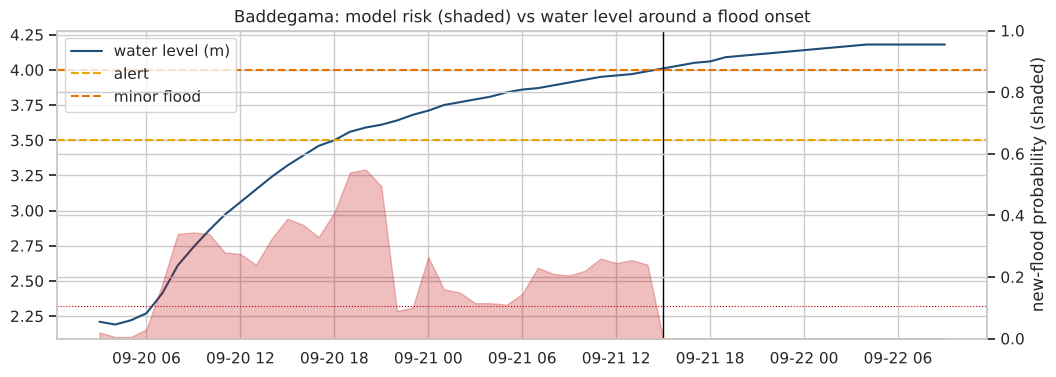

In [ ]:
g = data_all[(data_all.station == ev.station) & data_all.t.between(ev.onset - pd.Timedelta(hours=36), ev.onset + pd.Timedelta(hours=18))].copy()
g["score"] = np.where(g.is_flood == 1, np.nan, scores_of(best_model, g[FEATURES]))
s = stations.loc[ev.station]
fig, ax1 = plt.subplots(figsize=(12, 4))
ax1.plot(g.t, g.level, color="#1f4e79", label="water level (m)")
ax1.axhline(s.alert, color="#e6a700", ls="--", label="alert"); ax1.axhline(s.minor, color="#e67300", ls="--", label="minor flood")
ax2 = ax1.twinx(); ax2.fill_between(g.t, g.score.fillna(0), alpha=0.25, color="#c00000"); ax2.set_ylim(0, 1)
ax2.axhline(thresholds[BEST], color="#c00000", lw=0.8, ls=":"); ax2.set_ylabel("new-flood probability (shaded)")
ax1.axvline(ev.onset, color="black", lw=1); ax1.set_title(f"{ev.station}: model risk (shaded) vs water level around a flood onset")
ax1.legend(loc="upper left"); savefig("event_timeline"); plt.show()

## 10. Explainability with LIME


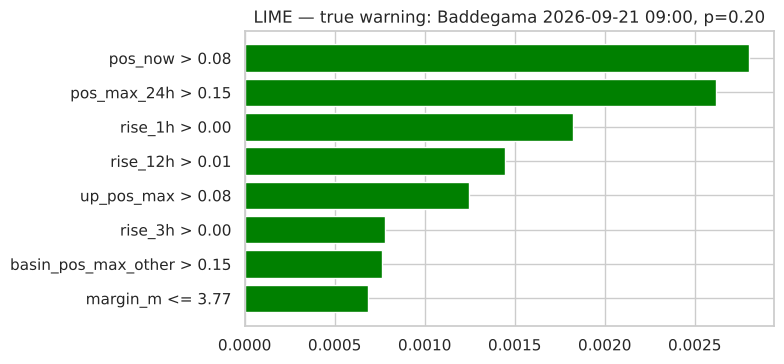

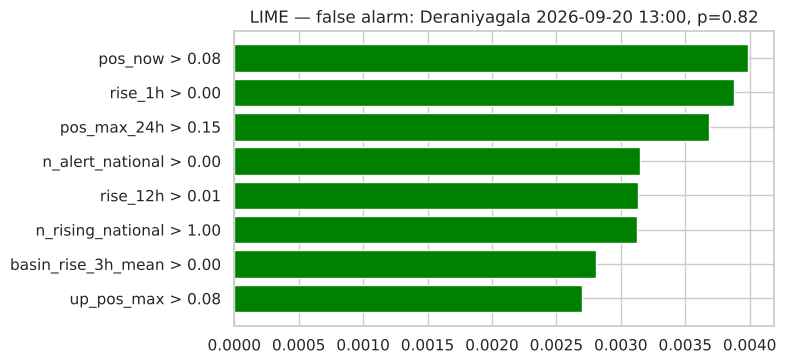

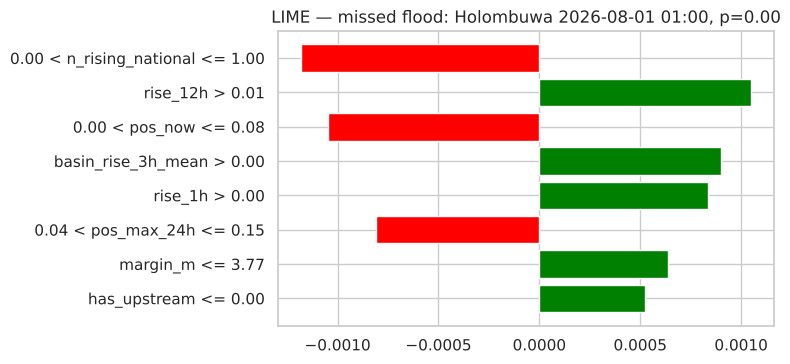

In [ ]:
from lime.lime_tabular import LimeTabularExplainer
lime_exp = LimeTabularExplainer(Xdev.values, feature_names=FEATURES, class_names=["no new flood", "new flood ≤6h"],
                                mode="classification", discretize_continuous=True, random_state=SEED)
def predict_fn(X):
    s = scores_of(best_model, pd.DataFrame(X, columns=FEATURES))
    if not hasattr(best_model, "predict_proba"):
        s = 1 / (1 + np.exp(-s))          # SVM margin -> pseudo-probability
    return np.c_[1 - s, s]

cases = {"true warning": row}
fa = te[(te.warn == 1) & (te.y == 0)]
miss = te[(te.warn == 0) & (te.y == 1)]
if len(fa): cases["false alarm"] = fa.sort_values("score", ascending=False).head(1)
if len(miss): cases["missed flood"] = miss.sort_values("score").head(1)
for label, r in cases.items():
    e = lime_exp.explain_instance(r[FEATURES].values[0], predict_fn, num_features=8, num_samples=3000)
    fig = e.as_pyplot_figure(); fig.set_size_inches(8, 3.8)
    plt.title(f"LIME — {label}: {r.station.iloc[0]} {r.t.iloc[0]:%Y-%m-%d %H:%M}, p={r.score.iloc[0]:.2f}")
    plt.tight_layout(); savefig("lime_" + label.replace(" ", "_")); plt.show()

In [ ]:
lime_w = dict(lime_exp.explain_instance(row[FEATURES].values[0], predict_fn, num_features=len(FEATURES), num_samples=3000).as_map()[1])
sv_cmp = pd.DataFrame({"value": row[FEATURES].values[0], "SHAP value": sv_row.values[0],
                       "LIME weight": [lime_w.get(i, 0) for i in range(len(FEATURES))]}, index=FEATURES)
sv_cmp["SHAP rank"] = sv_cmp["SHAP value"].abs().rank(ascending=False).astype(int)
sv_cmp["LIME rank"] = sv_cmp["LIME weight"].abs().rank(ascending=False).astype(int)
print("Rank agreement (Spearman) between SHAP and LIME:", round(sv_cmp["SHAP rank"].corr(sv_cmp["LIME rank"], method="spearman"), 2))
sv_cmp.sort_values("SHAP rank").round(3)

Rank agreement (Spearman) between SHAP and LIME: 0.0


,value,SHAP value,LIME weight,SHAP rank,LIME rank
n_rising_national,0.000,-0.155,0.000,1,15
pos_now,0.968,0.145,0.003,2,2
basin_rise_3h_mean,-0.094,-0.064,0.001,3,10
up_rise_3h_max,-0.206,-0.062,0.000,4,17
margin_m,2.830,-0.045,0.001,5,9
pos_max_24h,0.968,0.042,0.004,6,1
basin_pos_max_other,0.504,-0.025,0.001,7,7
pos_std_6h,0.013,-0.025,0.001,8,6
rise_1h,0.007,-0.022,0.002,9,3
up_pos_max,0.504,-0.020,0.001,10,12


### 10.1 Interpretation
**Global (SHAP).** The most important features are `pos_now` (how close the river is to its flood
level), `up_pos_max` (how high the upstream gauge is), `n_rising_national` (how many rivers are rising
across the country), `pos_max_24h` and `n_alert_national`. High values of each push risk up. A large
`margin_m` pushes risk down: rivers with a wide gap between normal and flood level rarely flood. The
model therefore combines three physical ideas: *is this river already high, is water coming from
upstream, and is a storm active?*

**Does this match domain knowledge (hydrology)?** Yes:
* Proximity to the flood stage (`pos_now`, `pos_max_24h`) dominating is how flood forecasters work:
  the closer the stage is to the flood level, the less extra water is needed.
* Upstream gauges (`up_pos_max`) matter because a flood wave travels downstream. The EDA measured
  that travel time directly (Glencourse → Hanwella about 3 hours).
* Many rivers rising at once (`n_rising_national`) is the signature of a widespread rain system such as
  a monsoon surge or cyclone, which also saturates catchments.
* A wide normal-to-flood margin (`margin_m`) lowering risk reflects large, deep river channels that
  need much more rain to overtop.
* One behaviour a hydrologist would question: a recent *fall* at the upstream gauge lowers risk even
  when this station is close to flooding (the Baddegama case). That is sensible on average but can be
  wrong when heavy local rain falls below the upstream gauge, the same blind spot as the missed flash flood.

**Local (SHAP waterfall).** At Baddegama (Gin Ganga) on 21 Sep 2026, 09:00 — 6 hours before it flooded —
the level was 3.91 m against a 4.0 m flood level. `pos_now` pushed risk up strongly; the absence of
rising rivers nationally and a *falling* upstream gauge (Thawalama) pushed it down. The net probability
(0.20) was still above the 0.105 threshold, so the model warned. The timeline shows the risk stayed
above threshold for more than a day as the river crept up.

**LIME vs SHAP.** LIME agrees that the level features (`pos_max_24h`, `pos_now`) matter most, but the
overall rank agreement is low and LIME's weights are tiny. LIME perturbs inputs by sampling typical
values from the training data — mostly calm rivers where risk is ≈0 — so its local linear surrogate is
almost flat around a rare, sharp flood boundary. This is a known weakness of LIME for rare-event,
non-linear models; SHAP's `TreeExplainer` is exact for tree ensembles and is the more trustworthy
explanation here. Using both, and seeing where they differ, is itself a useful check.

**Errors.** The highest-scoring false alarm is Deraniyagala on 20 Sep 2026: the river jumped 1.5 m in three
hours to 4.28 m during a national storm, then receded before its 5.8 m flood level — a near miss worth
knowing about. The clearest miss is Holombuwa (Gurugoda Oya) on 1 Aug 2026: at 01:00 the river was at its
normal level (0.50 m), then rose 3.2 m in four hours to 3.70 m, above its 3.4 m flood level. A flash flood
like this leaves no sign in river levels beforehand; only rainfall data could warn of it.

## 11. Save the model

In [ ]:
import joblib
lead_best = test_table.loc[BEST, ["onsets warned ≥1 h", "onsets warned ≥3 h", "median lead (h)"]].to_dict()
bundle = {"model": best_model, "model_name": BEST, "features": FEATURES, "threshold": float(thresholds[BEST]),
          "base_levels": base, "stations": stations, "horizon_h": HORIZON_H,
          "trained_until": str(TEST_START.date()), "test_metrics": test_table.loc[BEST].to_dict(), "lead_time": lead_best,
          "task": "new flood (river not yet at minor-flood level) reaches minor-flood level within 6 h"}
(ROOT / "models").mkdir(exist_ok=True)
# real example for the app's manual-input defaults: the explained warning hour
H = hourly.pivot_table(index="t", columns="station", values="level")
t0_, st_ = row.t.iloc[0], row.station.iloc[0]
lv = lambda h, stn=st_: float(H.at[t0_ - pd.Timedelta(hours=h), stn])
ups_ = stations.loc[st_, "upstream"]
bundle["example"] = {"station": st_, "label": f"{st_}, {t0_:%d %b %Y %H:%M} — {(ev.onset - t0_) / pd.Timedelta(hours=1):.0f} h before it reached flood level",
    "level_now": lv(0), "level_1h": lv(1), "level_3h": lv(3), "level_6h": lv(6), "level_12h": lv(12), "level_24h": lv(24),
    "max_24h": float(H[st_].loc[t0_ - pd.Timedelta(hours=23): t0_].max()),
    "up_now": lv(0, ups_[0]) if ups_ else None, "up_3h": lv(3, ups_[0]) if ups_ else None,
    "n_alert": int(row.n_alert_national.iloc[0]), "n_rise": int(row.n_rising_national.iloc[0])}
print(bundle["example"])
joblib.dump(bundle, ROOT / "models" / "flood_model.pkl", compress=3)
tuning.to_csv(ROOT / "reports" / "tuning_results.csv"); events.to_csv(ROOT / "reports" / "test_flood_events.csv", index=False)
sv_cmp.round(4).to_csv(ROOT / "reports" / "shap_vs_lime.csv")
reloaded = joblib.load(ROOT / "models" / "flood_model.pkl")
assert np.allclose(scores_of(reloaded["model"], Xte.head(500)), test_scores[BEST][:500])
print("Saved and reloaded models/flood_model.pkl —", BEST, "threshold", round(thresholds[BEST], 3))

{'station': 'Baddegama', 'label': 'Baddegama, 21 Sep 2026 09:00 — 6 h before it reached flood level', 'level_now': 3.91, 'level_1h': 3.89, 'level_3h': 3.86, 'level_6h': 3.79, 'level_12h': 3.61, 'level_24h': 2.74, 'max_24h': 3.91, 'up_now': 3.66, 'up_3h': 4.63, 'n_alert': 7, 'n_rise': 0}


Saved and reloaded models/flood_model.pkl — Extra Trees threshold 0.105


## 12. Critical discussion and conclusions
**Limitations of the model.**
* Only 11 months of data and a handful of storms; 187 of the 266 development flood hours come from one
  cyclone (Ditwah), so scores are noisy and the model has seen few storm types.
* River levels only: no rainfall, so flash floods with no prior rise (Holombuwa, 1 Aug 2026) are missed.
* Scores come from a class-balanced model and are not calibrated probabilities.
* A 6-hour horizon only, and minor floods only (major floods are not modelled separately).

**Data-quality issues.** 650 sensor spikes and drops to 0 m removed by the Hampel filter; day-long
outages affecting all stations (11 Mar and 7 Aug 2026); three stations report about half as often;
Nagalagam Street reports in feet (converted by the archive); the history exists only because a third
party archives the public dashboard, and thresholds are taken as published.

**Risks of bias** (section 8.2). Early warning is better for wet-zone rivers than for the
dry and intermediate zone, and 11 of 18 basins could not be evaluated at all. Wet-zone false alarms are
about 8× more frequent per gauge, which risks warning fatigue there.

**Real-world impact and ethical considerations.**
* Benefit: a median 4 hours of extra notice for new floods could allow evacuation and protection of
  property, using data the government already collects at no extra cost.
* Harm from errors: a missed flood can give false reassurance; frequent false alarms teach people to
  ignore warnings.
* Data ethics: the data is public, government-published river-sensor data about rivers, not people.
  It contains no personal or sensitive information.

**Conclusions.** Using only the river levels the Irrigation Department already publishes, the new
algorithm (Extra Trees) warns of every test-period flood onset at least an hour ahead (median 4 h) with
63% fewer false alarms than the alert-level rule. Reframing from "flood status in 6 h" to "new flood in
6 h" was the key modelling decision. SHAP and LIME show the model relies on physically sensible signals.